# Part 4. Interpretation

One held-out fold, three families. Grad-CAM targets passing **2 mm**; ViT/MAE
maps show CLS attention rollout. Maps are diagnostic, not proof of a shortcut.

In [1]:
import os, sys, json, hashlib, subprocess
from pathlib import Path
os.environ["USE_TF"] = "0"
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers==4.57.1", "wandb"])

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader
from kaggle_secrets import UserSecretsClient
import wandb

sys.path.insert(0, str(next(Path("/kaggle/input").rglob("soilcv/__init__.py")).parent.parent))
from soilcv.bags import make_grid_manifest, cache_grid, SampleBags, one_bag
from soilcv.data import load_metadata, load_folds, DEFAULT_FOLDS_PATH
from soilcv.curves import TARGET_COLUMNS
from soilcv.metrics import emd_per_sample
from soilcv.training import move_images
from soilcv.cnn.model import MILCNN, image_transform
from soilcv.vit.model import FullFrameModel
from soilcv.vit.images import make_photo_manifest, cache_photos, FullPhotoBags, photo_transform
from soilcv.ssl.model import SSLEncoder, SSLRegressor, make_head
from soilcv.ssl.data import TileTransform

wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"), verify=True)
api = wandb.Api()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FOLD = 0
OUT = Path("/kaggle/working/part4")
OUT.mkdir(parents=True, exist_ok=True)
DATA = next(Path("/kaggle/input").rglob("Training_labels_updated.csv")).parent
labels, photos, _ = load_metadata(DATA)
folds = load_folds(DEFAULT_FOLDS_PATH, labels.sample_id)
heldout = set(folds.loc[folds.fold.eq(FOLD), "sample_id"])
photos = photos[photos.sample_id.isin(heldout)].copy()
truth = labels.set_index("sample_id").loc[sorted(heldout)]
models, recipes, references = {}, {}, {}

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dmykhailov (dmykhailov-kyiv-school-of-economics) to https:/

## Checkpoints

One best checkpoint per model, not the Part 2 epoch ensemble. Mutable aliases
are resolved and recorded; assertions reject a different recipe/fold split.

In [2]:
cnn_art = api.artifact("public-team/soil-grain-size/mil-r18-cosine-fold-0:latest", type="model")
cnn_dir = Path(cnn_art.download(root=str(OUT / "cnn")))
cnn_cfg = dict(cnn_art.logged_by().config)
assert cnn_cfg["fold"] == FOLD and cnn_cfg["experiment_id"] == "mil-r18-cosine"
assert cnn_cfg["versions"]["soilcv"]["folds_hash"] == hashlib.sha256(DEFAULT_FOLDS_PATH.read_bytes()).hexdigest()
recipes["CNN"] = cnn_cfg["params"]
models["CNN"] = MILCNN(recipes["CNN"], recipes["CNN"]["train_mean_prior"], pretrained=False)
models["CNN"].load_state_dict(torch.load(cnn_dir / "weights.pt", map_location="cpu", weights_only=True))
references["CNN"] = cnn_art.qualified_name

vit_art = api.artifact("public-team/soil-grain-size/vit-scratch-p32-fold-0:latest", type="model")
vit_dir = Path(vit_art.download(root=str(OUT / "vit")))
vit_cfg = json.loads((vit_dir / "config.json").read_text())
assert vit_cfg["fold"] == FOLD and vit_cfg["experiment_id"] == "vit-scratch-p32"
assert vit_cfg["params"]["view_mode"] == "multiscale"
assert vit_cfg["versions"]["soilcv"]["folds_hash"] == cnn_cfg["versions"]["soilcv"]["folds_hash"]
recipes["ViT"] = vit_cfg["params"]
models["ViT"] = FullFrameModel(recipes["ViT"], recipes["ViT"]["train_mean_prior"], pretrained=False)
candidates = json.loads((vit_dir / "candidates.json").read_text())["candidates"]
best = min(candidates, key=lambda row: (row["emd"], row["epoch"]))
models["ViT"].load_state_dict(torch.load(vit_dir / best["weights"], map_location="cpu", weights_only=True))
references["ViT"] = {"artifact": vit_art.qualified_name, "epoch": best["epoch"]}

ssl_art = api.artifact("public-team/soil-grain-size/ssl-mae-fold-0:v1", type="model")
for filename in ["config.json", "weights.pt"]:
    ssl_art.get_path("mae/lpft/" + filename).download(root=str(OUT / "ssl"))
ssl_dir = OUT / "ssl/mae/lpft"
ssl_cfg = json.loads((ssl_dir / "config.json").read_text())
assert ssl_cfg["fold"] == FOLD and ssl_cfg["experiment"] == "mae-lpft"
assert ssl_cfg["identity"]["soilcv"]["folds_hash"] == cnn_cfg["versions"]["soilcv"]["folds_hash"]
encoder = SSLEncoder("mae", config=ssl_cfg["model_config"], pooling=ssl_cfg["pooling"])
models["SSL"] = SSLRegressor(encoder, make_head(encoder.output_dim, ssl_cfg["train_mean_prior"]))
models["SSL"].load_state_dict(torch.load(ssl_dir / "weights.pt", map_location="cpu", weights_only=True))
recipes["SSL"] = {"pixels": 224}
references["SSL"] = ssl_art.qualified_name
for model in models.values(): model.to(DEVICE).eval()
(OUT / "checkpoints.json").write_text(json.dumps(references, indent=2))

wandb:   1 of 1 files downloaded.  
wandb:   8 of 8 files downloaded.  
wandb: WARNING Artifact.get_path(name) is deprecated, use Artifact.get_entry(name) instead.


237

## Color-only control

Replace each tile/view by its mean RGB. Scale and pooling stay fixed; spatial
texture disappears while tile colors remain. Compare all six held-out soils.
This tests color reliance, not ruler/background reliance specifically.

In [3]:
loaders, grids = {}, {}
for name in models:
    recipe = recipes[name]
    grid = make_grid_manifest(photos, tile_mm=64, output_px=recipe["pixels"])
    cache_grid(grid, OUT / "tiles")
    grids[name] = grid
    if name == "ViT":
        frames = make_photo_manifest(photos, target_ppm=recipe["target_ppm"])
        cache_photos(frames, OUT / "tiles")
        dataset = FullPhotoBags(frames, OUT / "tiles", photo_transform(recipe),
                                tiles=grid, view_mode="multiscale")
    else:
        transform = image_transform(recipe) if name == "CNN" else TileTransform()
        dataset = SampleBags(grid, OUT / "tiles", transform)
    loaders[name] = DataLoader(dataset, batch_size=1, collate_fn=one_bag)


def color_only(images):
    if isinstance(images, list): return [color_only(image) for image in images]
    if isinstance(images, dict): return {key: color_only(value) for key, value in images.items()}
    return images.mean((-2, -1), keepdim=True).expand_as(images) if images.ndim >= 3 else images


rows = []
with torch.inference_mode():
    for name, model in models.items():
        for bag in loaders[name]:
            images = move_images(bag["image"], DEVICE)
            weights = bag["bag_weights"].to(DEVICE)
            baseline = model(images, weights).cpu().numpy()
            control = model(color_only(images), weights).cpu().numpy()
            target = truth.loc[[bag["sample_id"]], list(TARGET_COLUMNS)].to_numpy()
            rows.append({"model": name, "sample_id": bag["sample_id"],
                         "emd": emd_per_sample(target, baseline)[0],
                         "color_only_emd": emd_per_sample(target, control)[0],
                         "prediction_shift": emd_per_sample(baseline, control)[0]})
results = pd.DataFrame(rows)
results.to_csv(OUT / "control_per_sample.csv", index=False)
summary = results.groupby("model")[["emd", "color_only_emd", "prediction_shift"]].mean()
summary["delta_emd"] = summary.color_only_emd - summary.emd
summary.to_csv(OUT / "control_summary.csv")
display(summary.round(3))
conclusions = []
for name, row in summary.iterrows():
    conclusion = ("Spatial detail helps on this fold." if row.delta_emd > 0 else
                  "Removing texture did not worsen mean EMD; color shortcuts remain plausible.")
    conclusions.append(f"{name}: delta EMD {row.delta_emd:+.3f}. {conclusion}")
print("\n".join(conclusions))
(OUT / "conclusions.txt").write_text("\n".join(conclusions))

,emd,color_only_emd,prediction_shift,delta_emd
model,,,,
CNN,38.227,89.534,81.564,51.307
SSL,57.132,92.632,45.498,35.500
ViT,47.803,104.073,76.422,56.270


CNN: delta EMD +51.307. Spatial detail helps on this fold.
SSL: delta EMD +35.500. Spatial detail helps on this fold.
ViT: delta EMD +56.270. Spatial detail helps on this fold.


176

## Same physical crops: easy and failure cases

Choose lowest/highest mean baseline EMD across the three models. Show a central
64 mm tile from the same photo. These are tile-level maps, not full-bag causal
attributions; ViT also uses a global view. Brightness is not comparable between
methods. One fold and two displayed cases cannot rule out other shortcuts.

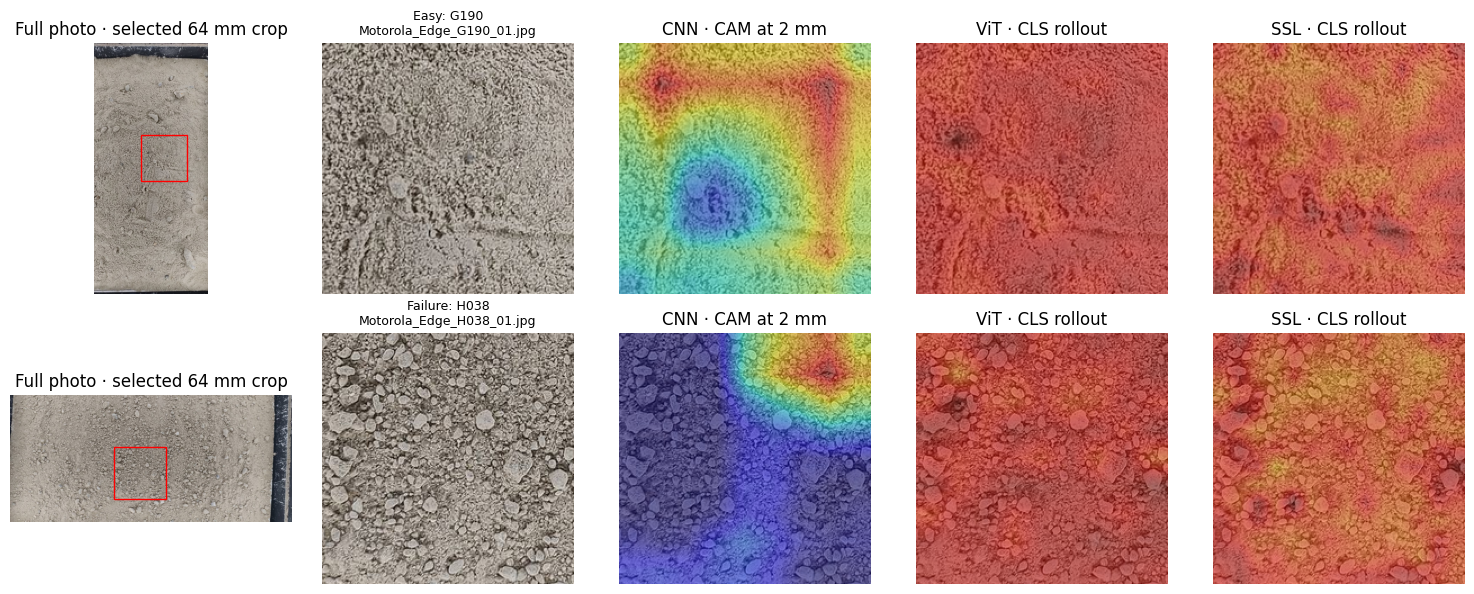

54

In [4]:
def cnn_cam(model, image):
    saved = []
    hook = model.encoder.layer4.register_forward_hook(lambda module, args, output: saved.append(output))
    try:
        image = image.detach().requires_grad_(True)
        curve = model(image, torch.ones(1, device=DEVICE))
        activation = saved[0]
        gradient = torch.autograd.grad(curve[0, list(TARGET_COLUMNS).index("2")], activation)[0]
        return (activation * gradient.mean((-2, -1), keepdim=True)).sum(1).relu()[0].detach()
    finally:
        hook.remove()


def vit_rollout(encoder, image):
    attention, hooks = [], []
    def capture(module, args):
        tokens, valid = args
        batch, length, dim = tokens.shape
        qkv = module.qkv(tokens).reshape(batch, length, 3, module.heads, dim // module.heads)
        q, k, _ = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        bias = torch.where(valid > 0, valid.log(), -torch.inf)
        attention.append(((q @ k.transpose(-2, -1)) / q.shape[-1]**.5 + bias).softmax(-1).mean(1)[0])
    for block in encoder.blocks:
        hooks.append(block.attention.register_forward_pre_hook(capture))
    try:
        with torch.no_grad(): encoder(image)
        joint = torch.eye(attention[0].shape[0], device=image.device)
        for matrix in attention:
            matrix = matrix + torch.eye(len(matrix), device=image.device)
            joint = (matrix / matrix.sum(-1, keepdim=True)) @ joint
        side = image.shape[-1] // encoder.patch_size
        return joint[0, 1:].reshape(side, side)
    finally:
        for hook in hooks: hook.remove()


def mae_rollout(encoder, image):
    encoder.backbone.set_attn_implementation("eager")
    patches = (image.shape[-1] // 16)**2
    noise = torch.arange(patches, device=image.device).float().expand(1, -1)
    with torch.no_grad():
        outputs = encoder.backbone(image, noise=noise, output_attentions=True)
    joint = torch.eye(patches + 1, device=image.device)
    for matrix in outputs.attentions:
        matrix = matrix.mean(1)[0] + torch.eye(patches + 1, device=image.device)
        joint = (matrix / matrix.sum(-1, keepdim=True)) @ joint
    return joint[0, 1:].reshape(image.shape[-1] // 16, -1)


ranked = results.groupby("sample_id").emd.mean().sort_values()
cases = [ranked.index[0], ranked.index[-1]]
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, sample in enumerate(cases):
    photo = photos[photos.sample_id.eq(sample)].sort_values("photo").iloc[0].photo
    crops = grids["SSL"].query("sample_id == @sample and photo == @photo")
    distance = (crops.left + crops.crop_px/2 - crops.width/2)**2 + (crops.top + crops.crop_px/2 - crops.height/2)**2
    tile_id = crops.loc[distance.idxmin()].tile_id
    tile = crops[crops.tile_id.eq(tile_id)].iloc[0]
    rgb = Image.open(OUT / "tiles" / tile.tile_path).convert("RGB")
    original = ImageOps.exif_transpose(Image.open(photos[photos.photo.eq(photo)].iloc[0].path)).convert("RGB")
    original.thumbnail((700, 700))
    sx, sy = original.width / tile.width, original.height / tile.height
    axes[row, 0].imshow(original)
    axes[row, 0].add_patch(Rectangle((tile.left*sx, tile.top*sy), tile.crop_px*sx, tile.crop_px*sy, fill=False, edgecolor="red"))
    axes[row, 0].set_title("Full photo · selected 64 mm crop")
    axes[row, 1].imshow(rgb)
    axes[row, 1].set_title(f"{'Easy' if row == 0 else 'Failure'}: {sample}\n{photo}", fontsize=9)
    for col, (name, model) in enumerate(models.items(), 2):
        tile = grids[name].query("sample_id == @sample and photo == @photo and tile_id == @tile_id").iloc[0]
        image = Image.open(OUT / "tiles" / tile.tile_path).convert("RGB")
        transform = image_transform(recipes[name]) if name == "CNN" else TileTransform()
        x = transform(image)[None].to(DEVICE)
        heat = cnn_cam(model, x) if name == "CNN" else (
               vit_rollout(model.encoder, x) if name == "ViT" else mae_rollout(model.encoder, x))
        heat = F.interpolate(heat[None, None].float(), size=(224, 224), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
        heat = heat / max(float(heat.max()), 1e-12)
        axes[row, col].imshow(rgb)
        axes[row, col].imshow(heat, cmap="jet", alpha=.45, vmin=0, vmax=1)
        axes[row, col].set_title(name + (" · CAM at 2 mm" if name == "CNN" else " · CLS rollout"))
        np.save(OUT / f"{sample}_{name}_map.npy", heat)
for axis in axes.flat: axis.axis("off")
plt.tight_layout()
fig.savefig(OUT / "interpretation.png", dpi=160)
plt.show()
(OUT / "cases.json").write_text(json.dumps({"fold": FOLD, "easy": cases[0], "failure": cases[1]}, indent=2))